In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload TikTok Survey file
uploaded = files.upload()

# Read the uploaded CSV file
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# Clean up column headings
df.columns = df.columns.str.strip()

# Remove completely empty rows
df = df.dropna(how="all")

# Find the question columns
question_columns = {
    "Q1": next(c for c in df.columns if c.startswith("Q1")),
    "Q2": next(c for c in df.columns if c.startswith("Q2")),
    "Q3": next(c for c in df.columns if c.startswith("Q3")),
    "Q4": next(c for c in df.columns if c.startswith("Q4")),
    "Q5": next(c for c in df.columns if c.startswith("Q5")),
    "Q6": next(c for c in df.columns if c.startswith("Q6"))
}

print("File loaded successfully!")
print("Number of respondents:", len(df))
print("Question columns:", question_columns)
print(df.head())

Saving Tiktok Survey - Sheet1.csv to Tiktok Survey - Sheet1.csv
File loaded successfully!
Number of respondents: 45
Question columns: {'Q1': 'Q1_Viewing', 'Q2': 'Q2_Trust', 'Q3': 'Q3_Reason', 'Q4': 'Q4_Followers', 'Q5': 'Q5_Paid_Promotions', 'Q6': 'Q6_Advice'}
   Respondent_ID Q1_Viewing Q2_Trust Q3_Reason Q4_Followers  \
0            1.0          A        E         E            E   
1            2.0          A        E         E            E   
2            3.0          C        B         B            C   
3            4.0          C        C         B            C   
4            5.0          D        C         D            A   

  Q5_Paid_Promotions Q6_Advice  
0                  E         E  
1                  E         E  
2                  D         B  
3                  B         B  
4                  A         B  



Q1 - Q1_Viewing
Valid answers: 45
              Answer  Count  Percentage (%)
            5–7 days     19            42.2
            3–4 days     12            26.7
              0 days      9            20.0
            1–2 days      4             8.9
Prefer not to answer      1             2.2


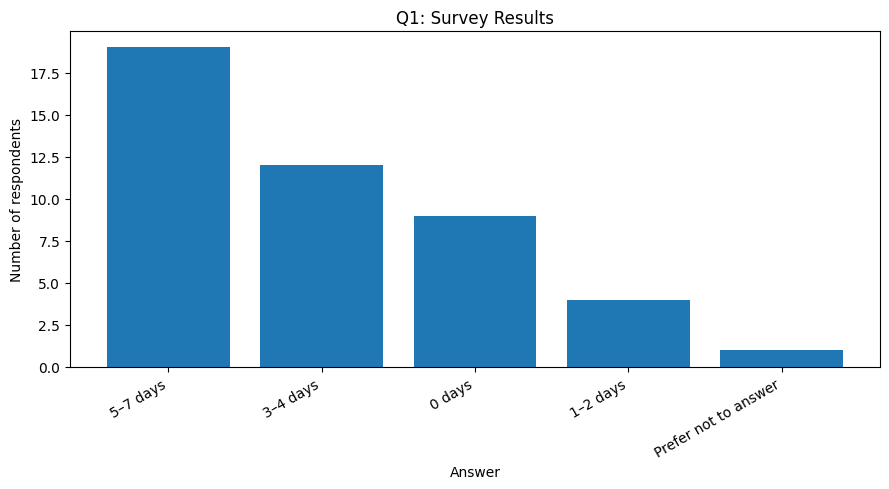


Q2 - Q2_Trust
Valid answers: 45
                  Answer  Count  Percentage (%)
                A little     16            35.6
                Somewhat     15            33.3
              Not at all      6            13.3
Do not watch influencers      4             8.9
                   A lot      4             8.9


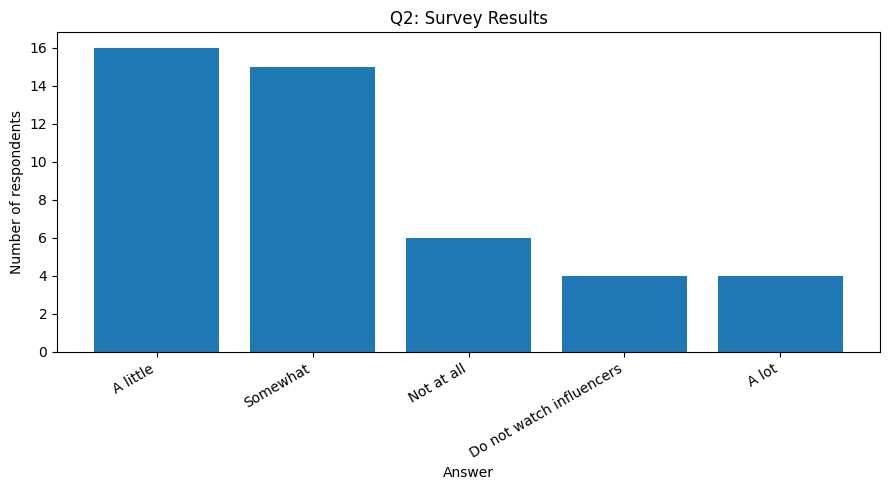


Q3 - Q3_Reason
Valid answers: 45
                    Answer  Count  Percentage (%)
                  Evidence     17            37.8
          Do not trust any      9            20.0
        Honest and genuine      7            15.6
            Another reason      6            13.3
                 Knowledge      5            11.1
Other/unusual entry: A & B      1             2.2


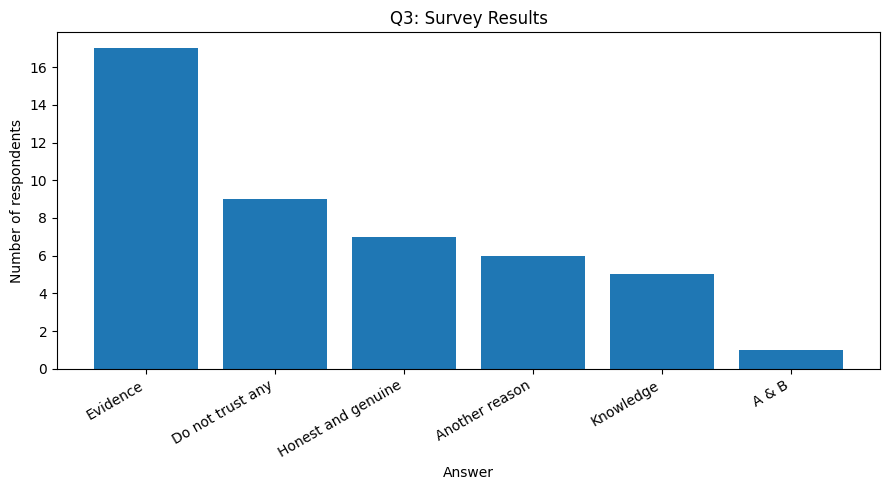


Q4 - Q4_Followers
Valid answers: 45
              Answer  Count  Percentage (%)
Moderately important     12            26.7
      Very important     12            26.7
       Not important     11            24.4
  Slightly important      7            15.6
      Not applicable      3             6.7


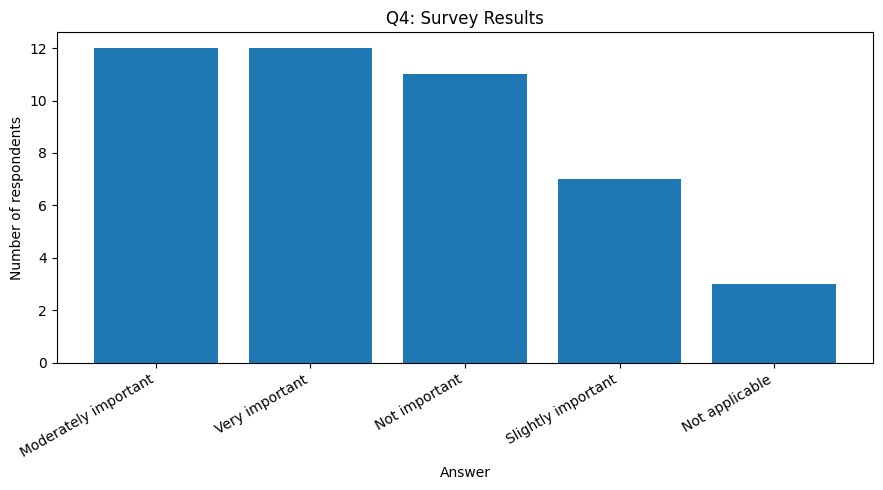


Q5 - Q5_Paid_Promotions
Valid answers: 45
              Answer  Count  Percentage (%)
  Slightly important     15            33.3
      Very important     12            26.7
Moderately important      7            15.6
       Not important      6            13.3
      Not applicable      5            11.1


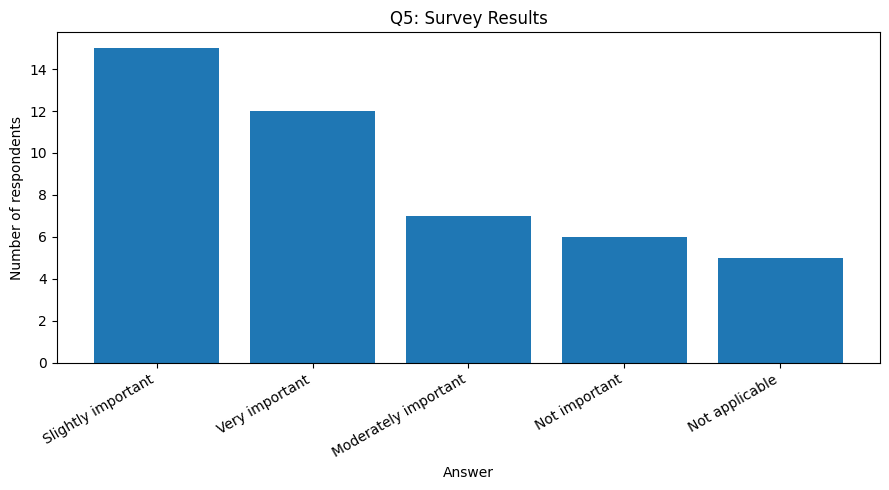


Q6 - Q6_Advice
Valid answers: 44
              Answer  Count  Percentage (%)
           1–2 times     24            54.5
             0 times     15            34.1
           3–5 times      3             6.8
Prefer not to answer      2             4.5


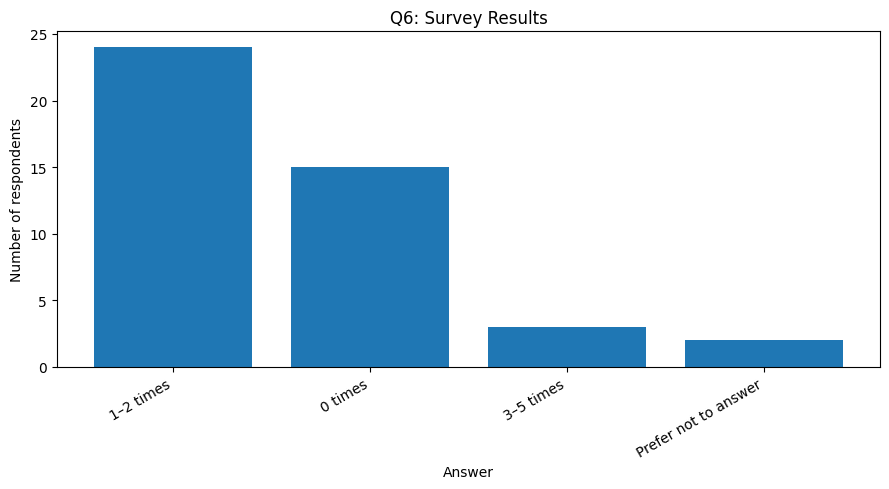

In [3]:
# Answer labels for each question
answer_labels = {
    "Q1": {
        "A": "0 days",
        "B": "1–2 days",
        "C": "3–4 days",
        "D": "5–7 days",
        "E": "Prefer not to answer"
    },
    "Q2": {
        "A": "Not at all",
        "B": "A little",
        "C": "Somewhat",
        "D": "A lot",
        "E": "Do not watch influencers"
    },
    "Q3": {
        "A": "Knowledge",
        "B": "Evidence",
        "C": "Honest and genuine",
        "D": "Another reason",
        "E": "Do not trust any"
    },
    "Q4": {
        "A": "Not important",
        "B": "Slightly important",
        "C": "Moderately important",
        "D": "Very important",
        "E": "Not applicable"
    },
    "Q5": {
        "A": "Not important",
        "B": "Slightly important",
        "C": "Moderately important",
        "D": "Very important",
        "E": "Not applicable"
    },
    "Q6": {
        "A": "0 times",
        "B": "1–2 times",
        "C": "3–5 times",
        "D": "6 or more times",
        "E": "Prefer not to answer"
    }
}

# Analyse every question
for q in ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"]:

    column = question_columns[q]

    # Exclude blank answers from calculations
    answers = df[column].dropna().astype(str).str.strip()
    answers = answers[answers != ""]

    # Count each answer
    counts = answers.value_counts()

    # Calculate percentages
    percentages = (counts / len(answers) * 100).round(1)

    # Create a results table
    results = pd.DataFrame({
        "Answer": [
            answer_labels[q].get(code, "Other/unusual entry: " + code)
            for code in counts.index
        ],
        "Count": counts.values,
        "Percentage (%)": percentages.values
    })

    print("\n" + "=" * 45)
    print(q, "-", column)
    print("Valid answers:", len(answers))
    print(results.to_string(index=False))

    # Draw a bar chart
    chart_labels = [
        answer_labels[q].get(code, code)
        for code in counts.index
    ]

    plt.figure(figsize=(9, 5))
    plt.bar(chart_labels, counts.values)
    plt.title(q + ": Survey Results")
    plt.xlabel("Answer")
    plt.ylabel("Number of respondents")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

Viewing Frequency vs Trust
Q2_Trust    A  B  C  D  E
Q1_Viewing               
A           4  0  1  2  2
B           0  3  1  0  0
C           1  5  5  1  0
D           1  8  8  1  1
E           0  0  0  0  1


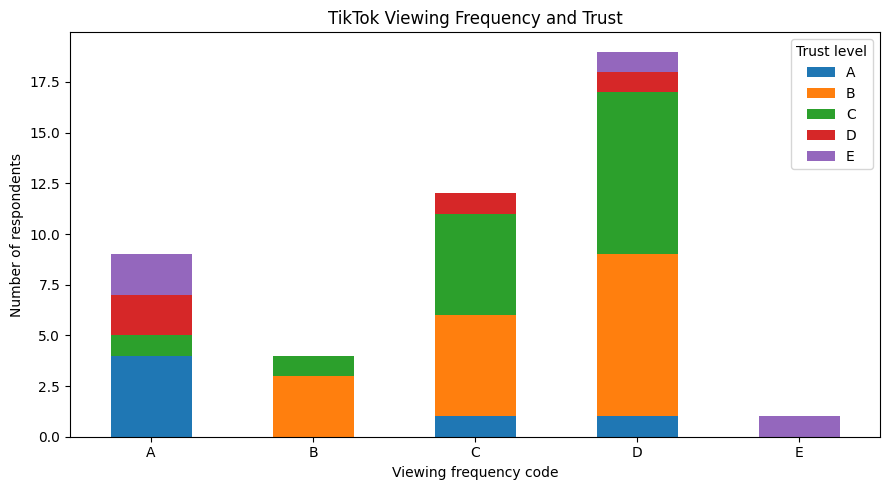

In [4]:
# Compare Q1 viewing frequency with Q2 trust
comparison = pd.crosstab(
    df[question_columns["Q1"]],
    df[question_columns["Q2"]]
)

print("Viewing Frequency vs Trust")
print(comparison)

# Visualise the comparison
comparison.plot(kind="bar", stacked=True, figsize=(9, 5))

plt.title("TikTok Viewing Frequency and Trust")
plt.xlabel("Viewing frequency code")
plt.ylabel("Number of respondents")
plt.legend(title="Trust level")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
print("Total rows:", len(df))

print("\nUnique respondent IDs:")
print(df.iloc[:, 0].nunique())

print("\nMissing answers per question:")
print(df[list(question_columns.values())].isna().sum())

print("\nAll recorded answers:")
for q, column in question_columns.items():
    print("\n", q)
    print(df[column].value_counts(dropna=False))

Total rows: 45

Unique respondent IDs:
45

Missing answers per question:
Q1_Viewing            0
Q2_Trust              0
Q3_Reason             0
Q4_Followers          0
Q5_Paid_Promotions    0
Q6_Advice             1
dtype: int64

All recorded answers:

 Q1
Q1_Viewing
D    19
C    12
A     9
B     4
E     1
Name: count, dtype: int64

 Q2
Q2_Trust
B    16
C    15
A     6
E     4
D     4
Name: count, dtype: int64

 Q3
Q3_Reason
B        17
E         9
C         7
D         6
A         5
A & B     1
Name: count, dtype: int64

 Q4
Q4_Followers
C    12
D    12
A    11
B     7
E     3
Name: count, dtype: int64

 Q5
Q5_Paid_Promotions
B    15
D    12
C     7
A     6
E     5
Name: count, dtype: int64

 Q6
Q6_Advice
B      24
A      15
C       3
E       2
NaN     1
Name: count, dtype: int64
